# TF-IDF (word + char) + XGBoost (spam w klasie negatywnej)

Wariant `spam_0`: wykrywamy tylko phishing, więc spam należy do klasy negatywnej (etykieta `label_spam_0`).

- **Cechy:** TF-IDF na n-gramach słów (1-2) i znaków (3-5), po 100 000 najczęstszych n-gramów w każdym słowniku. Następnie selekcja
  chi-kwadrat, bo przy 200 000 cech XGBoost nie mieści się w pamięci. Liczba wybranych cech jest częścią grida.
- **Dobór hiperparametrów:** grid z k-fold CV na zbiorze treningowym. Foldy są rozłączne względem klastrów, a TF-IDF i selekcja cech są
  uczone osobno w każdym foldzie. Kryterium to AUCPR ważone odwrotnością rozmiaru klastra,
  a liczba drzew jest dobierana wczesnym zatrzymaniem.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR ważonym klastrami nie większym niż 1%.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import itertools
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, WordCharTfidf, cluster_folds, cluster_weights, corpus_metrics, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)

EXPERIMENT = "tf_idf_xgb_spam_0"
LABEL = "label_spam_0"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

N_FOLDS = 3
FEATURE_COUNTS = (10_000, 20_000)
MAX_DEPTHS = (4, 6, 8)
LEARNING_RATES = (0.05, 0.1)
MAX_ROUNDS = 5000
EARLY_STOPPING_ROUNDS = 100
SEED = 42


def xgb_params(max_depth, learning_rate):
    # max_bin 32, bo przy 64 OOM na GPU
    return {
        "objective": "binary:logistic", "tree_method": "hist", "device": "cuda", "max_bin": 32,
        "max_depth": max_depth, "learning_rate": learning_rate, "seed": SEED,
    }

## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


## Grid z k-fold CV

Liczba drzew nie jest częścią siatki, tylko jest dobierana wczesnym zatrzymaniem (early stopping). W każdym foldzie model jest
uczony do `MAX_ROUNDS` drzew i zatrzymywany, gdy AUCPR ważone klastrami na części holdout nie rośnie przez `EARLY_STOPPING_ROUNDS`
kolejnych drzew. Wynik foldu to AUCPR dla najlepszej liczby drzew, a model końcowy dostaje średnią z tych liczb po foldach.

In [3]:
cv_rows = []
cv_start = time.perf_counter()
for fold, (fit_index, holdout_index) in enumerate(cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)):
    fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
    assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
    features = WordCharTfidf().fit(fit_frame.text, fit_frame[LABEL])
    fit_all, holdout_all = features.transform_all(fit_frame.text), features.transform_all(holdout_frame.text)
    holdout_weights = cluster_weights(holdout_frame.cluster)
    for n_features in FEATURE_COUNTS:
        selected = features.selected(n_features)
        dtrain = xgb.DMatrix(fit_all[:, selected], label=fit_frame[LABEL].to_numpy())
        dholdout = xgb.DMatrix(holdout_all[:, selected], label=holdout_frame[LABEL].to_numpy(), weight=holdout_weights)
        for max_depth, learning_rate in itertools.product(MAX_DEPTHS, LEARNING_RATES):
            start = time.perf_counter()
            booster = xgb.train(
                xgb_params(max_depth, learning_rate) | {"eval_metric": "aucpr"}, dtrain, num_boost_round=MAX_ROUNDS,
                evals=[(dholdout, "holdout")], early_stopping_rounds=EARLY_STOPPING_ROUNDS, verbose_eval=False,
            )
            n_estimators = booster.best_iteration + 1
            scores = booster.predict(dholdout, iteration_range=(0, n_estimators))
            cv_rows.append({
                "fold": fold, "n_features": n_features, "max_depth": max_depth, "learning_rate": learning_rate, "n_estimators": n_estimators,
                "aucpr_ważone": average_precision_score(holdout_frame[LABEL], scores, sample_weight=holdout_weights),
                "aucpr": average_precision_score(holdout_frame[LABEL], scores),
            })
            print(f"fold {fold}, {n_features} cech, depth {max_depth}, lr {learning_rate}: {n_estimators} drzew, {time.perf_counter() - start:.0f} s", flush=True)
            del booster
        del dtrain, dholdout
    del features, fit_all, holdout_all
cv_seconds = time.perf_counter() - cv_start

cv_folds = pd.DataFrame(cv_rows)
cv_folds.to_csv(TABLES / "cv_folds.csv", index=False)
GRID_COLUMNS = ["n_features", "max_depth", "learning_rate"]
cv_results = (
    cv_folds.groupby(GRID_COLUMNS)[["aucpr_ważone", "aucpr", "n_estimators"]].agg(["mean", "std"])
    .sort_values(("aucpr_ważone", "mean"), ascending=False)
)
cv_results.columns = [f"{metric}_{statistic}" for metric, statistic in cv_results.columns]
cv_results = cv_results.reset_index()
cv_results.to_csv(TABLES / "cv_results.csv", index=False)
best = cv_results.iloc[0]
print(f"Czas grida: {cv_seconds / 60:.1f} min")
display(cv_results.head(10))

fold 0, 10000 cech, depth 4, lr 0.05: 1727 drzew, 10 s


fold 0, 10000 cech, depth 4, lr 0.1: 1675 drzew, 10 s


fold 0, 10000 cech, depth 6, lr 0.05: 1009 drzew, 10 s


fold 0, 10000 cech, depth 6, lr 0.1: 726 drzew, 7 s


fold 0, 10000 cech, depth 8, lr 0.05: 1098 drzew, 16 s


fold 0, 10000 cech, depth 8, lr 0.1: 562 drzew, 9 s


... (28 outputs left out)

fold 2, 20000 cech, depth 8, lr 0.05: 1541 drzew, 43 s


fold 2, 20000 cech, depth 8, lr 0.1: 1104 drzew, 31 s


Czas grida: 20.4 min


,n_features,max_depth,learning_rate,aucpr_ważone_mean,aucpr_ważone_std,aucpr_mean,aucpr_std,n_estimators_mean,n_estimators_std
0,20000,6,0.0500,0.9381,0.0046,0.9360,0.0093,2193.3333,379.9610
1,20000,4,0.1000,0.9371,0.0042,0.9340,0.0079,1583.0000,630.6639
2,20000,8,0.0500,0.9366,0.0038,0.9352,0.0091,1597.6667,117.7172
3,20000,4,0.0500,0.9365,0.0051,0.9359,0.0099,2352.3333,883.9510
4,20000,8,0.1000,0.9359,0.0046,0.9345,0.0102,1013.6667,89.5116
5,20000,6,0.1000,0.9356,0.0022,0.9313,0.0092,715.0000,147.8276
6,10000,6,0.0500,0.9341,0.0050,0.9285,0.0072,1779.0000,699.7278
7,10000,4,0.0500,0.9339,0.0057,0.9260,0.0074,2674.3333,1251.4413
8,10000,8,0.0500,0.9336,0.0041,0.9306,0.0087,1254.3333,333.2422
9,10000,6,0.1000,0.9335,0.0038,0.9275,0.0050,984.0000,262.6157


## Uczenie modelu końcowego

Model z najlepszymi hiperparametrami jest uczony na całym zbiorze treningowym.

In [4]:
best_params = {
    "n_features": int(best.n_features), "max_depth": int(best.max_depth),
    "learning_rate": float(best.learning_rate), "n_estimators": int(round(best.n_estimators_mean)),
}
start = time.perf_counter()
features = WordCharTfidf().fit(train.text, train[LABEL])
selected = features.selected(best_params["n_features"])
booster = xgb.train(
    xgb_params(best_params["max_depth"], best_params["learning_rate"]),
    xgb.DMatrix(features.transform_all(train.text)[:, selected], label=train[LABEL].to_numpy()),
    num_boost_round=best_params["n_estimators"],
)
training_seconds = time.perf_counter() - start
print(best_params, f"czas uczenia: {training_seconds:.0f} s")


def score(frame):
    return booster.predict(xgb.DMatrix(features.transform_all(frame.text)[:, selected]))

{'n_features': 20000, 'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 2193} czas uczenia: 231 s


## Dobór progu na zbiorze walidacyjnym

In [5]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params,
    "aucpr_ważone_cv": best["aucpr_ważone_mean"], "czas_grida_s": cv_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,n_features,max_depth,learning_rate,n_estimators,aucpr_ważone_cv,czas_grida_s,czas_uczenia_s
0,0.0100,0.3564,0.0100,0.0204,0.9464,20000,6,0.0500,2193,0.9381,1223.9953,230.5601


## Metryki dla ID i OOD

In [6]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,1253.0000,0.9771,0.9010,0.8831,0.8658,0.9901,0.9305,0.0148
OOD,6124.0000,4987.0000,0.6292,0.6214,0.7318,0.8900,0.6975,0.9102,0.3369


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [7]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.9183,0.9183,0.9574,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.8537,0.8537,0.9211,1.0000,NaN,NaN,NaN
trec05,5386.0000,0.0000,0.9779,NaN,0.0000,0.0000,NaN,NaN,0.0221
trec06,1582.0000,0.0000,0.9867,NaN,0.0000,0.0000,NaN,NaN,0.0133
trec07,4849.0000,0.0000,0.9928,NaN,0.0000,0.0000,NaN,NaN,0.0072
ferb,5601.0000,4707.0000,0.6227,0.6184,0.7337,0.9018,0.6779,0.9247,0.3546
kd10000,60.0000,55.0000,0.7000,0.6727,0.8043,1.0000,0.9818,0.9984,0.0000
nebulon,145.0000,69.0000,0.6552,0.4638,0.5614,0.7111,0.7571,0.7165,0.1711
zeroday,318.0000,156.0000,0.7170,0.7628,0.7256,0.6919,0.8422,0.8631,0.3272


## Macierze pomyłek i krzywe

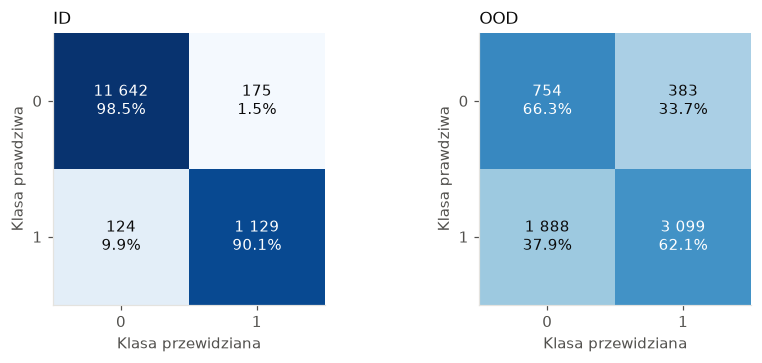

,przewidziane 0,przewidziane 1
prawdziwe 0,11642,175
prawdziwe 1,124,1129


,przewidziane 0,przewidziane 1
prawdziwe 0,754,383
prawdziwe 1,1888,3099


In [8]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

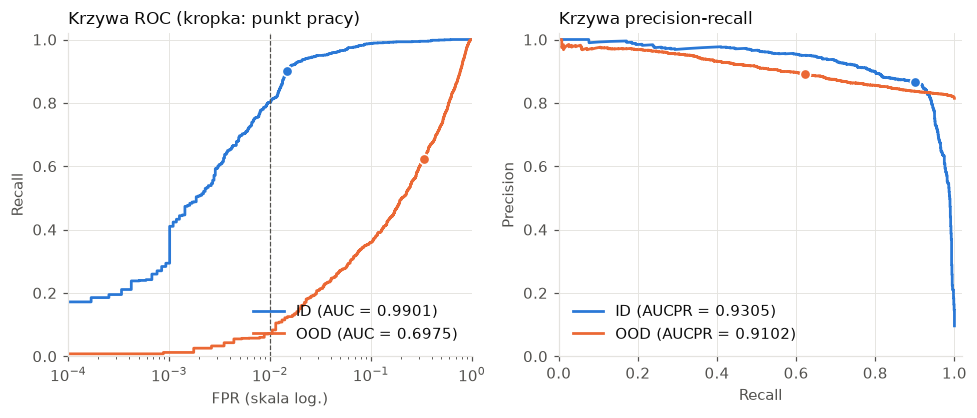

In [9]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")